# Assignment 10: PCA and LDA on Handwritten Digits

**Dataset:** `sklearn.datasets.load_digits()`  
**Task:** Dimensionality reduction and multiclass classification  
**Total marks:** 20

The Digits dataset contains 1,797 images, 64 input features, and 10 classes. PCA can return up to 64 components, while LDA can return at most $10-1=9$ components.

## Assignment rules

1. Use a stratified 70/15/15 split with random state 42.
2. Fit the scaler, PCA, LDA, and classifier only on training data.
3. Implement the core PCA and LDA calculations using NumPy.
4. Use validation data to select dimensionality or other experimental choices.
5. Use the test set only once for the final selected configurations.
6. Keep all tables, figures, and outputs visible in the submitted notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## Task 1 — Load the Digits dataset, print its shapes and class counts, and display one image from each class. **[1 mark]**

Dataset shape: (1797, 64)
Target shape: (1797,)
Images shape: (1797, 8, 8)

Class distribution:
Digit 0: 178
Digit 1: 182
Digit 2: 177
Digit 3: 183
Digit 4: 181
Digit 5: 182
Digit 6: 181
Digit 7: 179
Digit 8: 174
Digit 9: 180


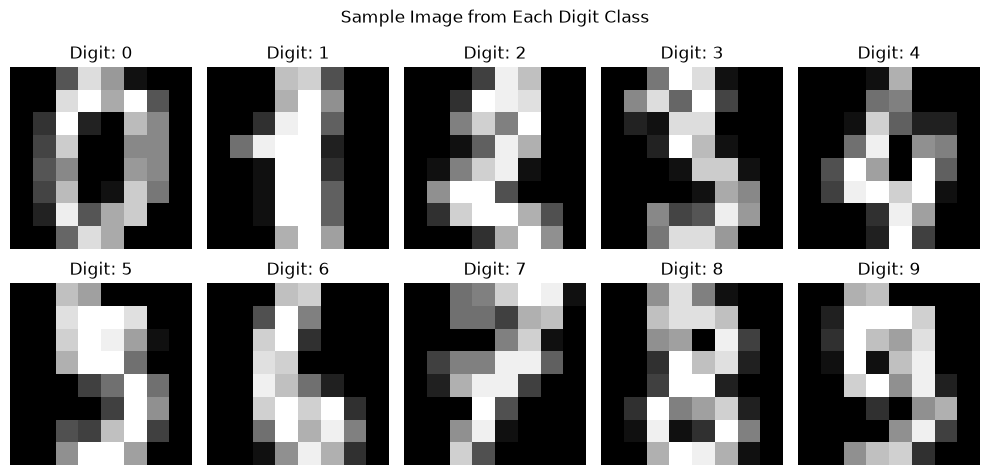

In [2]:
# Task 1 solution
# Write your code here.
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data
y = digits.target
images = digits.images

# Dataset shapes
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Images shape:", images.shape)

# Class count
classes, counts = np.unique(y, return_counts=True)

print("\nClass distribution:")
for digit, count in zip(classes, counts):
    print(f"Digit {digit}: {count}")
    
# Sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit, ax in enumerate(axes.ravel()):
    index = np.where(y == digit)[0][0]
    ax.imshow(images[index], cmap="gray")
    ax.set_title(f"Digit: {digit}")
    ax.axis("off")

plt.suptitle("Sample Image from Each Digit Class")
plt.tight_layout()

## Task 2 — Create a stratified 70/15/15 split and standardize features using statistics learned only from training data. **[2 marks]**

In [3]:
# Task 2 solution
# Write your code here.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Stratified 70:15:15 split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_SEED)

# Standardize features using training stats
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Print split shapes
print("Training set:, X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Validation set: X_val:", X_val.shape, "| y_val:", y_val.shape)
print("Testing set: X_test:", X_test.shape, "| y_test:", y_test.shape)

# Print standardized feature statistics
print("\nStandardized feature statistics:")
print("Training mean:", np.mean(X_train_scaled))
print("Training standard deviation:", np.std(X_train_scaled))
print("Validation mean:", np.mean(X_val_scaled))
print("Validation standard deviation:", np.std(X_val_scaled))
print("Testing mean:", np.mean(X_test_scaled))
print("Testing standard deviation:", np.std(X_test_scaled))

Training set:, X_train: (1257, 64) | y_train: (1257,)
Validation set: X_val: (270, 64) | y_val: (270,)
Testing set: X_test: (270, 64) | y_test: (270,)

Standardized feature statistics:
Training mean: 9.185616114639322e-18
Training standard deviation: 0.9682458365518538
Validation mean: 0.021680053046072213
Validation standard deviation: 1.1466034506653613
Testing mean: -0.01574836964443066
Testing standard deviation: 0.9237565889728524


## Task 3 — Implement PCA from scratch using covariance and eigendecomposition, then verify eigenvalue ordering and component shapes. **[3 marks]**

In [4]:
# Task 3 solution
# Write your code here.
def pca_fit(X):
    # Compute covariance matrix
    cov_matrix = np.cov(X, rowvar=False)

    # Perform eigendecomposition
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    # Sort eigenvalues and eigenvectors in descending order
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    components = eigenvectors[:, sorted_indices]

    return eigenvalues, components, cov_matrix

def pca_transform(X, components, n_components=None):
    # Select the required principal components
    if n_components is None:
        n_components = components.shape[1]

    selected_components = components[:, :n_components]

    # Project data onto principal components
    return X @ selected_components

In [5]:
# Fit PCA using training data only
pca_eigenvalues, pca_components, cov_matrix = pca_fit(X_train_scaled)

# Transform training and validation data
X_train_pca = pca_transform(X_train_scaled, pca_components)
X_val_pca = pca_transform(X_val_scaled, pca_components)

# Verify shapes and eigenvalue ordering
print("Covariance matrix shape:", cov_matrix.shape)
print("Eigenvalues shape:", pca_eigenvalues.shape)
print("PCA components shape:", pca_components.shape)

print("\nFirst 10 eigenvalues:")
print(pca_eigenvalues[:10])

print("\nEigenvalues sorted in descending order:", np.all(np.diff(pca_eigenvalues) <= 0))
print("All eigenvalues non-negative:", np.all(pca_eigenvalues >= -1e-10))
print("PCA components are orthonormal:", np.allclose(pca_components.T @ pca_components, np.eye(64), atol=1e-6))

print("\nTraining PCA shape:", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)

Covariance matrix shape: (64, 64)
Eigenvalues shape: (64,)
PCA components shape: (64, 64)

First 10 eigenvalues:
[7.28433948 5.90782286 5.08641651 4.153268   2.95497513 2.70236419
 2.3875099  2.01773039 1.831867   1.79361956]

Eigenvalues sorted in descending order: True
All eigenvalues non-negative: True
PCA components are orthonormal: True

Training PCA shape: (1257, 64)
Validation PCA shape: (270, 64)


## Task 4 — Plot explained and cumulative variance, and determine the smallest PCA dimension retaining at least 95% variance. **[2 marks]**

Explained variance ratio (first 10 components):
[0.12130907 0.09838538 0.08470617 0.06916606 0.04921041 0.04500357
 0.03976018 0.03360209 0.03050683 0.02986988]

Cumulative explained variance (first 10 components):
[0.12130907 0.21969446 0.30440062 0.37356669 0.42277709 0.46778067
 0.50754084 0.54114293 0.57164976 0.60151963]

Minimum components required for 95% variance: 39
Variance retained: 95.2006365836905 %


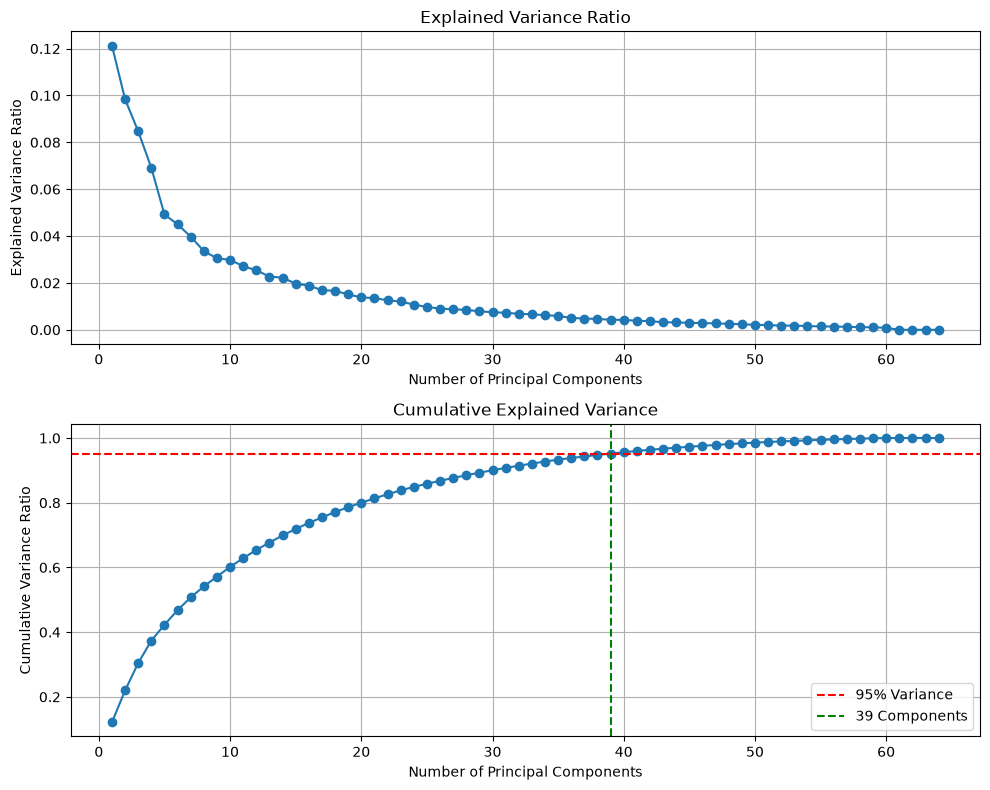

In [6]:
# Task 4 solution
# Write your code here.

# Calculate explained and cumulative variance ratios
explained_variance_ratio = pca_eigenvalues / np.sum(pca_eigenvalues)
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

# Determine minimum components required for 95% variance
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1

print("Explained variance ratio (first 10 components):")
print(explained_variance_ratio[:10])

print("\nCumulative explained variance (first 10 components):")
print(cumulative_variance_ratio[:10])

print("\nMinimum components required for 95% variance:", n_components_95)
print("Variance retained:", cumulative_variance_ratio[n_components_95 - 1] * 100, "%")

# Plot explained and cumulative variance
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Individual explained variance
axes[0].plot(
    np.arange(1, 65),
    explained_variance_ratio,
    marker="o"
)
axes[0].set_title("Explained Variance Ratio")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].grid(True)

# Cumulative explained variance
axes[1].plot(
    np.arange(1, 65),
    cumulative_variance_ratio,
    marker="o"
)
axes[1].axhline(y=0.95, color="red", linestyle="--", label="95% Variance")
axes[1].axvline(x=n_components_95, color="green", linestyle="--", label=f"{n_components_95} Components")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Variance Ratio")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("plots/exp_n_cum_variance.png")

## Task 5 — Implement LDA from scratch using $S_W$ and $S_B$, include numerical regularization, and reduce the data to at most nine components. **[4 marks]**

In [7]:
# Task 5 solution
# Write your code here.
def lda_fit(X, y, regularization=1e-4):
    # Identify classes and compute overall mean
    classes = np.unique(y)
    n_features = X.shape[1]
    overall_mean = np.mean(X, axis=0)

    # Initialize within-class and between-class scatter matrices
    S_W = np.zeros((n_features, n_features))
    S_B = np.zeros((n_features, n_features))

    # Compute within-class and between-class scatter
    for cls in classes:
        X_cls = X[y == cls]
        class_mean = np.mean(X_cls, axis=0)
        n_cls = X_cls.shape[0]

        # Within-class scatter
        centered = X_cls - class_mean
        S_W += centered.T @ centered

        # Between-class scatter
        mean_diff = (class_mean - overall_mean).reshape(-1, 1)
        S_B += n_cls * (mean_diff @ mean_diff.T)

    # Apply numerical regularization
    alpha = regularization * np.trace(S_W) / n_features
    S_W_reg = S_W + alpha * np.eye(n_features)

    # Solve generalized eigenvalue problem
    eigenvalues, eigenvectors = np.linalg.eig(np.linalg.solve(S_W_reg, S_B))

    # Convert numerical results to real values
    eigenvalues = np.real_if_close(eigenvalues).real
    eigenvectors = np.real_if_close(eigenvectors).real

    # Sort eigenvalues and eigenvectors in descending order
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    components = eigenvectors[:, sorted_indices]

    # Retain at most C-1 discriminant components
    n_components = min(len(classes) - 1, n_features)
    eigenvalues = eigenvalues[:n_components]
    components = components[:, :n_components]

    return eigenvalues, components, S_W, S_B, S_W_reg

def lda_transform(X, components, n_components=None):
    # Select the required discriminant components
    if n_components is None:
        n_components = components.shape[1]

    selected_components = components[:, :n_components]

    # Project data onto discriminant directions
    return X @ selected_components

In [8]:
# Fit LDA using training data only
lda_eigenvalues, lda_components, S_W, S_B, S_W_reg = lda_fit(X_train_scaled, y_train)

# Transform training and validation data
X_train_lda = lda_transform(X_train_scaled, lda_components)
X_val_lda = lda_transform(X_val_scaled, lda_components)

# Verify scatter matrices and component shapes
print("Within-class scatter matrix shape:", S_W.shape)
print("Between-class scatter matrix shape:", S_B.shape)
print("Regularized S_W shape:", S_W_reg.shape)

print("\nLDA eigenvalues shape:", lda_eigenvalues.shape)
print("LDA components shape:", lda_components.shape)

print("\nLDA eigenvalues:")
print(lda_eigenvalues)

print("\nEigenvalues sorted in descending order:", np.all(np.diff(lda_eigenvalues) <= 0))

print("\nTraining LDA shape:", X_train_lda.shape)
print("Validation LDA shape:", X_val_lda.shape)

print("\nRegularization parameter:", 1e-4 * np.trace(S_W) / X_train_scaled.shape[1])

Within-class scatter matrix shape: (64, 64)
Between-class scatter matrix shape: (64, 64)
Regularized S_W shape: (64, 64)

LDA eigenvalues shape: (9,)
LDA components shape: (64, 9)

LDA eigenvalues:
[7.60662365 4.93550269 4.42312979 3.06802318 2.12275069 1.75204631
 1.11247199 0.81573272 0.55862622]

Eigenvalues sorted in descending order: True

Training LDA shape: (1257, 9)
Validation LDA shape: (270, 9)

Regularization parameter: 0.08069355111963891


## Task 6 — Compare scratch and Scikit-learn PCA/LDA using component counts, projection shapes, and validation classification accuracy. **[2 marks]**

In [9]:
# Task 6 solution
# Write your code here.
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression

# Select component counts
pca_n_components = n_components_95
lda_n_components = len(np.unique(y_train)) - 1

# Scikit-learn PCA
sklearn_pca = PCA(n_components=pca_n_components)
X_train_pca_sklearn = sklearn_pca.fit_transform(X_train_scaled)
X_val_pca_sklearn = sklearn_pca.transform(X_val_scaled)

# Scikit-learn LDA
sklearn_lda = LinearDiscriminantAnalysis(n_components=lda_n_components)
X_train_lda_sklearn = sklearn_lda.fit_transform(X_train_scaled, y_train)
X_val_lda_sklearn = sklearn_lda.transform(X_val_scaled)

# Prepare scratch and Scikit-learn projections
projections = {
    "Scratch PCA": (
        pca_transform(X_train_scaled, pca_components, pca_n_components),
        pca_transform(X_val_scaled, pca_components, pca_n_components)
    ),
    "Sklearn PCA": (
        X_train_pca_sklearn, X_val_pca_sklearn
    ),
    "Scratch LDA": (
        lda_transform(X_train_scaled, lda_components, lda_n_components),
        lda_transform(X_val_scaled, lda_components, lda_n_components)
    ),
    "Sklearn LDA": (
        X_train_lda_sklearn, X_val_lda_sklearn
    )
}

# Train and evaluate the same classifier for each projection
results = []

for method, (X_train_projected, X_val_projected) in projections.items():
    classifier = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)
    classifier.fit(X_train_projected, y_train)

    accuracy = classifier.score(X_val_projected, y_val)

    results.append({
        "Method": method,
        "Components": X_train_projected.shape[1],
        "Train Projection Shape": X_train_projected.shape,
        "Validation Projection Shape": X_val_projected.shape,
        "Validation Accuracy": accuracy
    })

# Display comparison
results_df = pd.DataFrame(results)
display(results_df)

,Method,Components,Train Projection Shape,Validation Projection Shape,Validation Accuracy
0,Scratch PCA,39,"(1257, 39)","(270, 39)",0.966667
1,Sklearn PCA,39,"(1257, 39)","(270, 39)",0.966667
2,Scratch LDA,9,"(1257, 9)","(270, 9)",0.955556
3,Sklearn LDA,9,"(1257, 9)","(270, 9)",0.955556


## Task 7 — Plot the first two PCA and LDA components with digit classes shown in different colours. **[1 mark]**

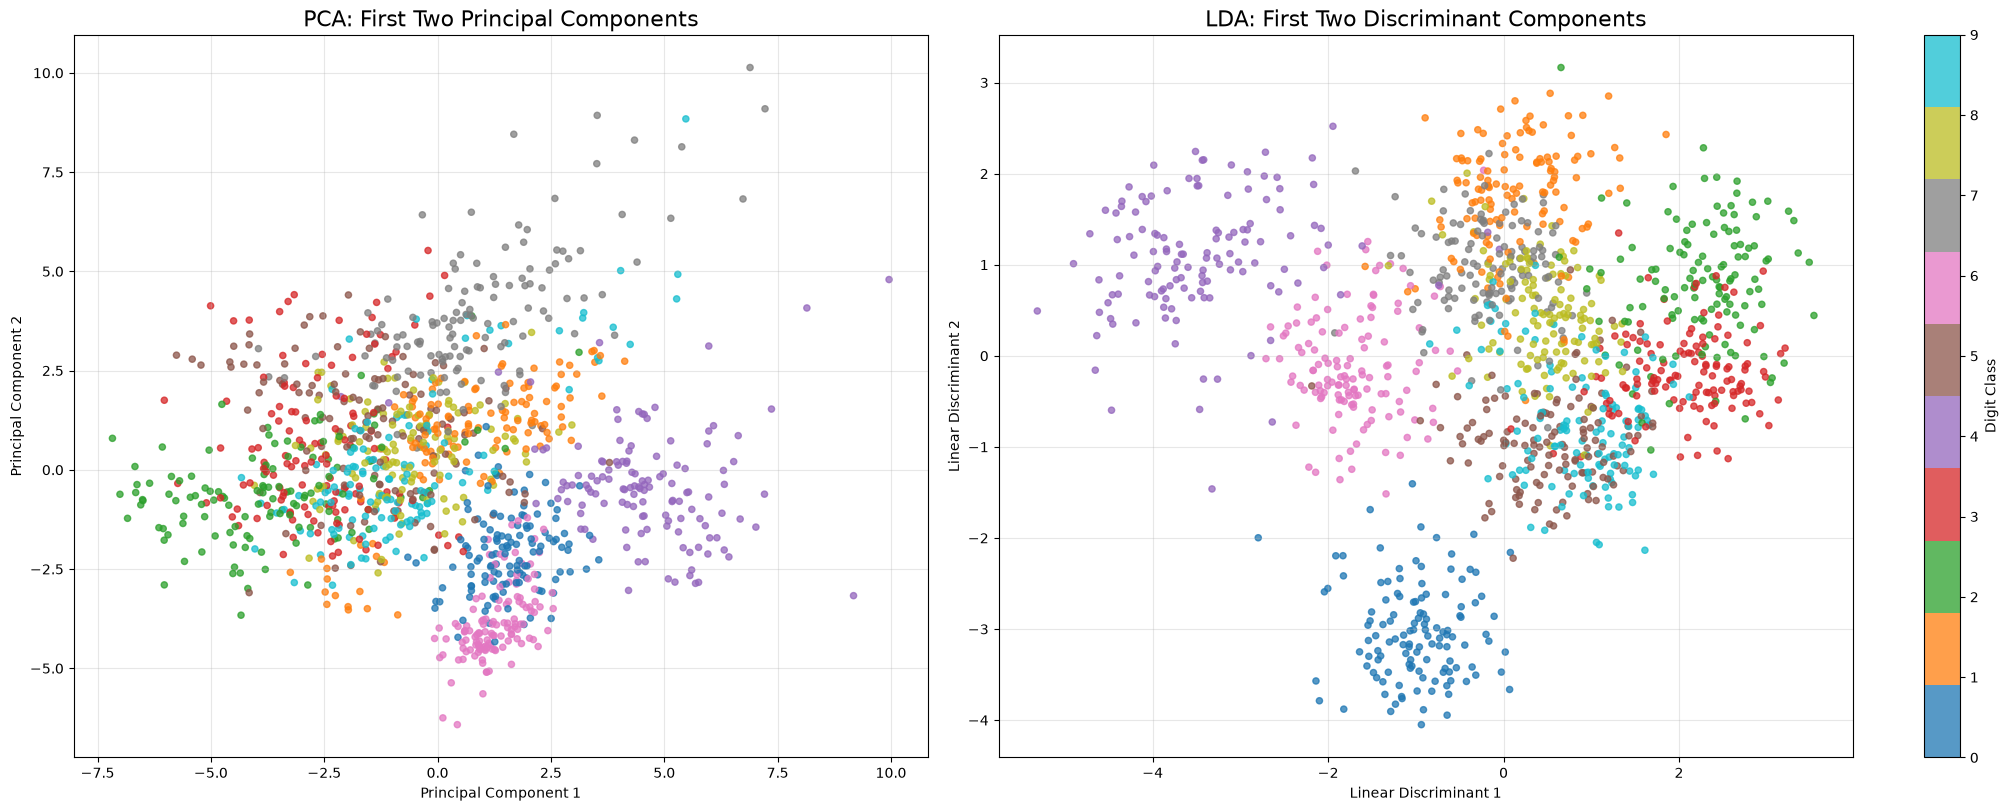

In [10]:
# Task 7 solution
# Write your code here.
# Project training data onto the first two components
X_train_pca_2d = pca_transform(X_train_scaled, pca_components, n_components=2)
X_train_lda_2d = lda_transform(X_train_scaled, lda_components, n_components=2)

# Create PCA and LDA scatter plots
fig, axes = plt.subplots(1, 2, figsize=(20, 8), constrained_layout=True)

scatter_pca = axes[0].scatter(
    X_train_pca_2d[:, 0],
    X_train_pca_2d[:, 1],
    c=y_train,
    cmap="tab10",
    s=20,
    alpha=0.75
)
axes[0].set_title("PCA: First Two Principal Components", fontsize=16)
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(alpha=0.3)

scatter_lda = axes[1].scatter(
    X_train_lda_2d[:, 0],
    X_train_lda_2d[:, 1],
    c=y_train,
    cmap="tab10",
    s=20,
    alpha=0.75
)
axes[1].set_title("LDA: First Two Discriminant Components", fontsize=16)
axes[1].set_xlabel("Linear Discriminant 1")
axes[1].set_ylabel("Linear Discriminant 2")
axes[1].grid(alpha=0.3)

# Add a common colour bar for digit classes
colorbar = fig.colorbar(scatter_lda, ax=axes, ticks=np.arange(10), fraction=0.025, pad=0.04)
colorbar.set_label("Digit Class")
plt.savefig("plots/first_two_components.png")

## Task 8 — Compare Logistic Regression on full features, 95%-variance PCA features, and nine LDA features using validation data. **[2 marks]**

In [11]:
# Task 8 solution
# Write your code here.=

# Pick principal components with 95% variance
X_train_pca = pca_transform(X_train_scaled, pca_components, 39)
X_val_pca = pca_transform(X_val_scaled, pca_components, 39)

# Prepare the three feature representations
feature_sets = {
    "Full Features": (X_train_scaled, X_val_scaled),
    "PCA (95% Variance)": (X_train_pca, X_val_pca),
    "LDA (9 Components)": (X_train_lda, X_val_lda)
}

# Train and evaluate Logistic Regression
results = []

for method, (X_train_features, X_val_features) in feature_sets.items():
    classifier = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)
    classifier.fit(X_train_features, y_train)

    accuracy = classifier.score(X_val_features, y_val)

    results.append({
        "Feature Representation": method,
        "Number of Features": X_train_features.shape[1],
        "Validation Accuracy": accuracy
    })

# Display comparison
results_df = pd.DataFrame(results)
display(results_df)

,Feature Representation,Number of Features,Validation Accuracy
0,Full Features,64,0.977778
1,PCA (95% Variance),39,0.966667
2,LDA (9 Components),9,0.955556


## Task 9 — Evaluate the selected configurations once on the test set using accuracy, macro precision, recall, F1-score, training time, and confusion matrices. **[2 marks]**

In [16]:
# Task 9 solution
# Write your code here.
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Prepare test feature representations
X_test_pca = pca_transform(X_test_scaled, pca_components, 39)
X_test_lda = lda_transform(X_test_scaled, lda_components, 9)

# Prepare selected configurations
feature_sets = {
    "Full Features": (X_train_scaled, X_test_scaled),
    "PCA (95% Variance)": (X_train_pca, X_test_pca),
    "LDA (9 Components)": (X_train_lda, X_test_lda)
}

# Initialize evaluation results and confusion matrices
results = []
confusion_matrices = {}

# Train and evaluate each configuration
for method, (X_train_features, X_test_features) in feature_sets.items():

    # Train Logistic Regression and measure training time
    classifier = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)

    start_time = time.perf_counter()
    classifier.fit(X_train_features, y_train)
    training_time = time.perf_counter() - start_time

    # Predict test labels
    y_test_pred = classifier.predict(X_test_features)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)

    # Store results
    results.append({
        "Method": method,
        "Features": X_train_features.shape[1],
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1,
        "Training Time (s)": training_time
    })

    # Store confusion matrix
    confusion_matrices[method] = confusion_matrix(y_test, y_test_pred, labels=np.arange(10))

# Display final evaluation results
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Method,Features,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (s)
0,Full Features,64,0.9852,0.9854,0.9850,0.9852,0.1014
1,PCA (95% Variance),39,0.9593,0.9601,0.9588,0.9591,0.0844
2,LDA (9 Components),9,0.9556,0.9569,0.9553,0.9552,0.0368


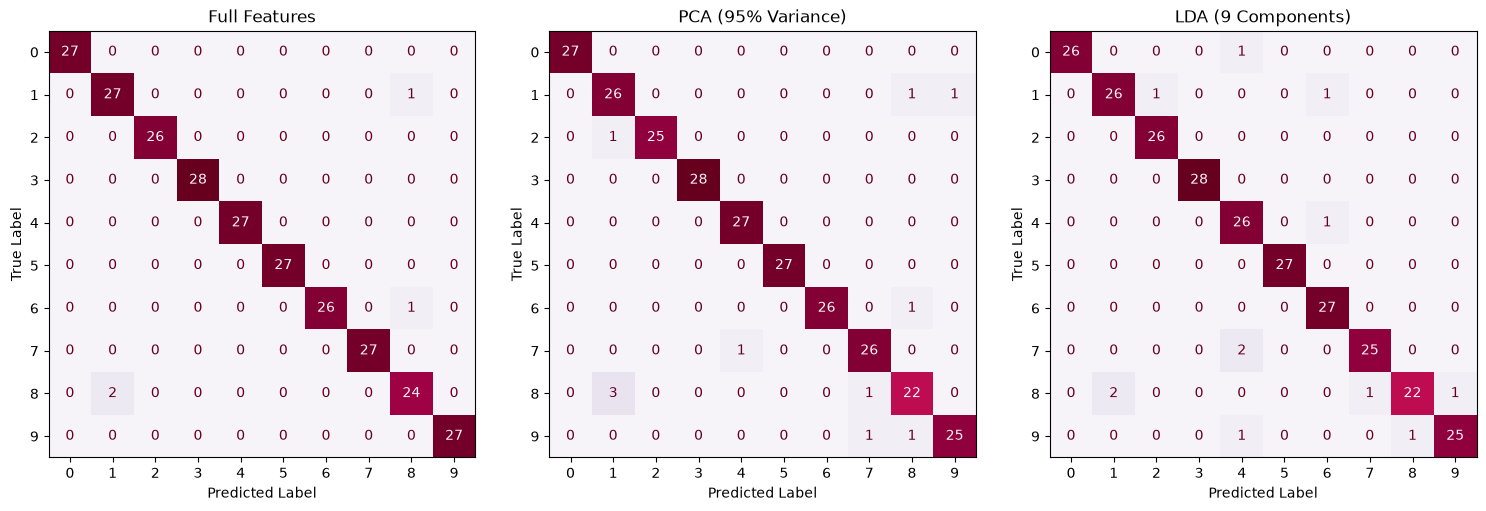

In [17]:
# Plot confusion matrices for all three configurations
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

for ax, (method, cm) in zip(axes, confusion_matrices.items()):
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
    display.plot(ax=ax, cmap="PuRd", colorbar=False, values_format="d")

    ax.set_title(method)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

# Save and display the figure
plt.savefig("plots/test_confusion_matrices.png")

## Task 10 — Write a five-point comparison explaining when PCA or LDA should be preferred, supported by your measured results. **[1 mark]**

In [ ]:
# Task 10 solution
# Write your answer here as comments or add a Markdown cell.

| Aspect | PCA | LDA |
|---|---|---|
| **Objective** | Unsupervised technique that preserves maximum overall data variance. | Supervised technique that maximizes class separability using class labels. |
| **Dimensionality Reduction** | Reduced 64 features to 39 components, retaining 95.20% variance. | Reduced 64 features to 9 components (maximum \(C-1\) components for 10 classes). |
| **Classification Performance** | Achieved 95.93% test accuracy. | Achieved 95.56% test accuracy. |
| **Computational Efficiency** | Logistic Regression training took 0.0844 seconds. | Logistic Regression training took 0.0368 seconds. |
| **When to Prefer** | When preserving overall data information and reducing dimensionality without using class labels are important. | When compact, class-discriminative representations and faster classifier training are desired. |

**Overall Conclusion:** PCA provides a good balance between dimensionality reduction and classification performance, whereas LDA offers greater compression and computational efficiency. The choice depends on whether preserving overall variance or maximizing class discrimination is more important.

## Assignment marks distribution

| Task | Component | Marks |
|---:|---|---:|
| 1 | Dataset inspection and visualization | 1 |
| 2 | Leakage-free split and standardization | 2 |
| 3 | PCA from scratch | 3 |
| 4 | Variance analysis and component selection | 2 |
| 5 | LDA from scratch | 4 |
| 6 | Scikit-learn verification | 2 |
| 7 | PCA/LDA visualization | 1 |
| 8 | Validation classification comparison | 2 |
| 9 | Final test evaluation | 2 |
| 10 | Interpretation | 1 |
|  | **Total** | **20** |

---
End of the assignment